# Лабораторная работа №4
## Нейронные сети и современные подходы

**Вариант:** 10  
**Датасет:** ISEAR — Emotion Detection  
**Классы:** joy, fear, anger, sadness, disgust, shame, guilt  
**Методы:** TF-IDF, статические эмбеддинги, Sentence-Transformers  
**Визуализация:** PCA → t-SNE и PCA → UMAP

## 1. Окружение и воспроизводимость

In [1]:
from pathlib import Path
import json
import logging
import platform
import re
import string
import subprocess
import sys
import time
import warnings

import cloudpickle
import gensim.downloader as gensim_api
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import umap.umap_ as umap
from datasets import load_dataset
from IPython.display import display
from sentence_transformers import SentenceTransformer
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score,
    classification_report, confusion_matrix, f1_score, roc_auc_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler, label_binarize
from sklearn.manifold import TSNE

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_STATE)

cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd.parent if cwd.name == "notebooks" else cwd
if not (PROJECT_ROOT / ".git").exists():
    raise RuntimeError("Запустите Notebook из корня репозитория или папки notebooks.")

RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed" / "lab4"
MODEL_DIR = PROJECT_ROOT / "models"
REPORT_DIR = PROJECT_ROOT / "reports" / "lab4"
FIGURE_DIR = REPORT_DIR / "figures"
for directory in (RAW_DIR, PROCESSED_DIR, MODEL_DIR, REPORT_DIR, FIGURE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
branch = subprocess.run(["git", "branch", "--show-current"], cwd=PROJECT_ROOT,
                        capture_output=True, text=True).stdout.strip()
print(f"Корень проекта: {PROJECT_ROOT}")
print(f"Ветка: {branch}")
print(f"Python: {platform.python_version()}")
print(f"PyTorch: {torch.__version__}")
print(f"Устройство: {DEVICE}")
if DEVICE == "cpu":
    print("CUDA недоступна: расчёты выполняются на CPU, что разрешено условием задания.")

C:\Users\Доктор Варвар\Desktop\все\MWwithD\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Корень проекта: C:\Users\Доктор Варвар\Desktop\все\MWwithD
Ветка: fix/all-labs-requirements
Python: 3.11.9
PyTorch: 2.15.0+cpu
Устройство: cpu
CUDA недоступна: расчёты выполняются на CPU, что разрешено условием задания.


## 2. Загрузка и подготовка ISEAR

Используется восстановленная из оригинала версия ISEAR:
`savalera/isear-from-original`, конфигурация `filtered`. Она удаляет пустые и
некорректные ответы, сохраняя исходные семь эмоций и официальное разбиение.

In [2]:
dataset = load_dataset("savalera/isear-from-original", "filtered")

def to_frame(split):
    frame = dataset[split].to_pandas()[["SIT", "Field1"]].copy()
    frame.columns = ["text", "emotion"]
    frame["text"] = frame["text"].astype(str).str.strip()
    frame["emotion"] = frame["emotion"].astype(str).str.lower().str.strip()
    return frame.dropna().drop_duplicates(subset=["text", "emotion"]).reset_index(drop=True)

train_df = to_frame("train")
validation_df = to_frame("validation")
test_df = to_frame("test")
all_df = pd.concat([train_df, validation_df, test_df], ignore_index=True)

expected_emotions = {"joy", "fear", "anger", "sadness", "disgust", "shame", "guilt"}
assert set(all_df["emotion"].unique()) == expected_emotions
assert all_df["text"].str.len().gt(0).all()

raw_path = RAW_DIR / "isear_lab4.csv"
train_path = PROCESSED_DIR / "train.csv"
validation_path = PROCESSED_DIR / "validation.csv"
test_path = PROCESSED_DIR / "test.csv"
all_df.to_csv(raw_path, index=False)
train_df.to_csv(train_path, index=False)
validation_df.to_csv(validation_path, index=False)
test_df.to_csv(test_path, index=False)

print(f"Всего после фильтрации: {len(all_df)}")
print(f"Train: {len(train_df)}, validation: {len(validation_df)}, test: {len(test_df)}")
display(train_df.head())
display(all_df["emotion"].value_counts().to_frame("count"))

Всего после фильтрации: 7319
Train: 5853, validation: 732, test: 734


,text,emotion
0,When my friend was punished for something that...,guilt
1,One evening when a boy who was drunk made a pa...,disgust
2,"When some people, including me, are treated in...",disgust
3,When I saw that I had passed the university en...,joy
4,"A young, close relative of mine died, leaving ...",sadness


,count
emotion,
anger,1066
disgust,1057
guilt,1054
fear,1051
shame,1045
joy,1044
sadness,1002


## 3. Предобработка и исследовательский анализ

Для TF-IDF и статических эмбеддингов текст приводится к нижнему регистру,
очищается от пунктуации и английских стоп-слов. Sentence-Transformer получает
минимально очищенный исходный текст, поскольку модель использует контекст.

,count,mean,median
emotion,,,
anger,1066,24.90,22.0
disgust,1057,21.75,18.0
fear,1051,24.36,22.0
guilt,1054,23.94,21.0
joy,1044,20.30,17.0
sadness,1002,21.18,17.5
shame,1045,22.65,20.0


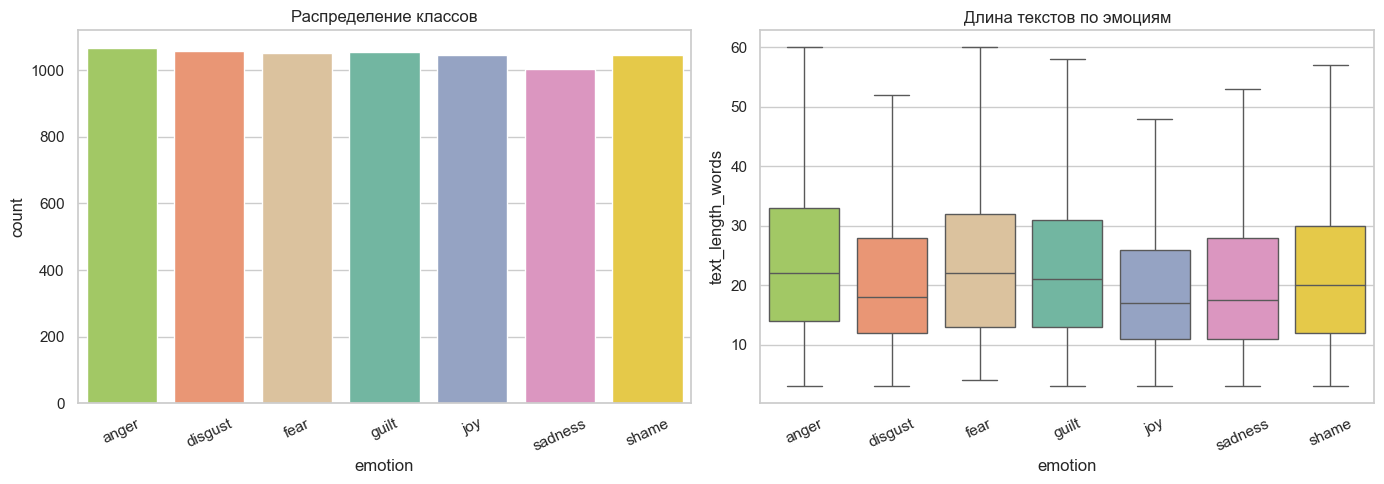

Сохранено: reports\lab4\figures\dataset_overview.png


In [3]:
stop_words = set(ENGLISH_STOP_WORDS)

def preprocess_text(text):
    text = text.lower()
    text = re.sub(r"[^a-z\s']", " ", text)
    tokens = [token for token in text.split() if token not in stop_words and len(token) > 1]
    return " ".join(tokens)

for frame in (train_df, validation_df, test_df):
    frame["clean_text"] = frame["text"].map(preprocess_text)

label_encoder = LabelEncoder()
label_encoder.fit(sorted(expected_emotions))
y_train = label_encoder.transform(train_df["emotion"])
y_validation = label_encoder.transform(validation_df["emotion"])
y_test = label_encoder.transform(test_df["emotion"])
class_names = label_encoder.classes_.tolist()

all_df["text_length_words"] = all_df["text"].str.split().str.len()
display(all_df.groupby("emotion")["text_length_words"].agg(["count", "mean", "median"]).round(2))

def save_figure(name):
    path = FIGURE_DIR / name
    plt.tight_layout(); plt.savefig(path, dpi=160, bbox_inches="tight")
    plt.show(); plt.close()
    print(f"Сохранено: {path.relative_to(PROJECT_ROOT)}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(data=all_df, x="emotion", order=class_names, hue="emotion",
              palette="Set2", legend=False, ax=axes[0])
axes[0].set_title("Распределение классов"); axes[0].tick_params(axis="x", rotation=25)
sns.boxplot(data=all_df, x="emotion", y="text_length_words", order=class_names,
            hue="emotion", palette="Set2", legend=False, ax=axes[1], showfliers=False)
axes[1].set_title("Длина текстов по эмоциям"); axes[1].tick_params(axis="x", rotation=25)
save_figure("dataset_overview.png")

## 4. Baseline: TF-IDF + LogisticRegression

Используются униграммы и биграммы, `max_features=10000`. Параметр C выбирается
только по validation, test остаётся нетронутым до финальной оценки.

In [4]:
tfidf_candidates = [0.5, 1.0, 2.0, 5.0]
tfidf_rows = []
tfidf_models = {}
for c_value in tfidf_candidates:
    model = Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), max_features=10000,
                                  min_df=2, sublinear_tf=True)),
        ("classifier", LogisticRegression(C=c_value, max_iter=3000,
                                          random_state=RANDOM_STATE)),
    ])
    start = time.perf_counter()
    model.fit(train_df["clean_text"], y_train)
    elapsed = time.perf_counter() - start
    pred = model.predict(validation_df["clean_text"])
    proba = model.predict_proba(validation_df["clean_text"])
    tfidf_rows.append({
        "C": c_value,
        "accuracy": accuracy_score(y_validation, pred),
        "f1_macro": f1_score(y_validation, pred, average="macro"),
        "roc_auc_macro_ovr": roc_auc_score(y_validation, proba,
                                            multi_class="ovr", average="macro"),
        "fit_seconds": elapsed,
    })
    tfidf_models[c_value] = model

tfidf_search = pd.DataFrame(tfidf_rows).sort_values(
    ["f1_macro", "roc_auc_macro_ovr"], ascending=False)
best_tfidf_c = float(tfidf_search.iloc[0]["C"])
best_tfidf = tfidf_models[best_tfidf_c]
tfidf_search.to_csv(REPORT_DIR / "tfidf_validation.csv", index=False)
display(tfidf_search)
print(f"Лучший TF-IDF C: {best_tfidf_c}")

,C,accuracy,f1_macro,roc_auc_macro_ovr,fit_seconds
1,1.0,0.581967,0.576400,0.875994,0.616431
2,2.0,0.580601,0.574796,0.874573,0.612757
0,0.5,0.579235,0.572841,0.875081,0.226570
3,5.0,0.573770,0.569056,0.869258,0.527578


Лучший TF-IDF C: 1.0


## 5. Статические предобученные эмбеддинги

Через `gensim.downloader` загружается предобученная модель
`fasttext-wiki-news-subwords-300`, прямо предусмотренная требованиями.
FastText является статическим словарным представлением и умеет строить
векторы для редких слов по символьным подсловам. Вектор документа — среднее
векторов его слов.

In [5]:
static_vectors_name = "fasttext-wiki-news-subwords-300"
logging.getLogger("gensim").setLevel(logging.WARNING)
static_vectors = gensim_api.load(static_vectors_name)
STATIC_DIM = static_vectors.vector_size

def document_vectors(clean_texts, vectors):
    result = np.zeros((len(clean_texts), vectors.vector_size), dtype=np.float32)
    coverage = []
    for row_index, text in enumerate(clean_texts):
        tokens = text.split()
        known = [vectors[token] for token in tokens if token in vectors]
        coverage.append(len(known) / max(1, len(tokens)))
        if known:
            result[row_index] = np.mean(known, axis=0)
    return result, np.asarray(coverage)

static_train, coverage_train = document_vectors(train_df["clean_text"], static_vectors)
static_validation, coverage_validation = document_vectors(validation_df["clean_text"], static_vectors)
static_test, coverage_test = document_vectors(test_df["clean_text"], static_vectors)
print(f"Среднее покрытие словаря train: {coverage_train.mean():.3f}")
print(f"Документов без известных слов: {(coverage_train == 0).sum()}")

static_rows, static_models = [], {}
for c_value in [0.1, 1.0, 10.0]:
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(C=c_value, max_iter=3000,
                                          random_state=RANDOM_STATE)),
    ])
    start = time.perf_counter(); model.fit(static_train, y_train)
    elapsed = time.perf_counter() - start
    pred = model.predict(static_validation); proba = model.predict_proba(static_validation)
    static_rows.append({
        "C": c_value,
        "accuracy": accuracy_score(y_validation, pred),
        "f1_macro": f1_score(y_validation, pred, average="macro"),
        "roc_auc_macro_ovr": roc_auc_score(y_validation, proba,
                                            multi_class="ovr", average="macro"),
        "fit_seconds": elapsed,
    })
    static_models[c_value] = model
static_search = pd.DataFrame(static_rows).sort_values(
    ["f1_macro", "roc_auc_macro_ovr"], ascending=False)
best_static_c = float(static_search.iloc[0]["C"])
best_static = static_models[best_static_c]
static_search.to_csv(REPORT_DIR / "static_embeddings_validation.csv", index=False)
display(static_search)

Среднее покрытие словаря train: 0.973
Документов без известных слов: 0


,C,accuracy,f1_macro,roc_auc_macro_ovr,fit_seconds
1,1.0,0.551913,0.546964,0.839461,0.310123
0,0.1,0.551913,0.546323,0.844981,0.231305
2,10.0,0.545082,0.540252,0.838522,0.347532


## 6. Современные Sentence-Transformer эмбеддинги

`all-MiniLM-L6-v2` создаёт контекстные векторы предложений размерности 384.
При наличии CUDA используется GPU; в текущем окружении автоматически выбран CPU.

In [6]:
sentence_model_name = "sentence-transformers/all-MiniLM-L6-v2"
sentence_model = SentenceTransformer(sentence_model_name, device=DEVICE)

def encode_texts(texts):
    return sentence_model.encode(
        texts.tolist(), batch_size=64, show_progress_bar=True,
        convert_to_numpy=True, normalize_embeddings=True)

start = time.perf_counter()
sentence_train = encode_texts(train_df["text"])
sentence_validation = encode_texts(validation_df["text"])
sentence_test = encode_texts(test_df["text"])
sentence_encoding_seconds = time.perf_counter() - start
print(f"Форма эмбеддингов: {sentence_train.shape}")
print(f"Время кодирования: {sentence_encoding_seconds:.1f} с")

sentence_rows, sentence_models = [], {}
for c_value in [0.1, 1.0, 10.0]:
    model = LogisticRegression(C=c_value, max_iter=3000, random_state=RANDOM_STATE)
    start = time.perf_counter(); model.fit(sentence_train, y_train)
    elapsed = time.perf_counter() - start
    pred = model.predict(sentence_validation); proba = model.predict_proba(sentence_validation)
    sentence_rows.append({
        "C": c_value,
        "accuracy": accuracy_score(y_validation, pred),
        "f1_macro": f1_score(y_validation, pred, average="macro"),
        "roc_auc_macro_ovr": roc_auc_score(y_validation, proba,
                                            multi_class="ovr", average="macro"),
        "fit_seconds": elapsed,
    })
    sentence_models[c_value] = model
sentence_search = pd.DataFrame(sentence_rows).sort_values(
    ["f1_macro", "roc_auc_macro_ovr"], ascending=False)
best_sentence_c = float(sentence_search.iloc[0]["C"])
best_sentence = sentence_models[best_sentence_c]
sentence_search.to_csv(REPORT_DIR / "sentence_embeddings_validation.csv", index=False)
display(sentence_search)

Batches:   0%|          | 0/92 [00:00<?, ?it/s]

Batches:   1%|          | 1/92 [00:00<01:27,  1.04it/s]

Batches:   2%|▏         | 2/92 [00:01<00:59,  1.51it/s]

Batches:   3%|▎         | 3/92 [00:01<00:47,  1.87it/s]

Batches:   4%|▍         | 4/92 [00:02<00:40,  2.19it/s]

Batches:   5%|▌         | 5/92 [00:02<00:34,  2.49it/s]

... (92 outputs left out)

Batches:  92%|█████████▏| 11/12 [00:02<00:00,  8.63it/s]

Batches: 100%|██████████| 12/12 [00:02<00:00,  5.38it/s]

Форма эмбеддингов: (5853, 384)
Время кодирования: 18.8 с


,C,accuracy,f1_macro,roc_auc_macro_ovr,fit_seconds
1,1.0,0.627049,0.624399,0.901361,0.242002
2,10.0,0.621585,0.620627,0.900395,0.431950
0,0.1,0.594262,0.589023,0.882544,0.119528


## 7. Сравнение подходов на validation

,method,accuracy,f1_macro,roc_auc_macro_ovr,fit_seconds
2,Sentence-Transformers,0.627049,0.624399,0.901361,0.242002
0,TF-IDF,0.581967,0.576400,0.875994,0.616431
1,Static (fasttext-wiki-news-subwords-300),0.551913,0.546964,0.839461,0.310123


Лучший метод по validation F1-macro: Sentence-Transformers


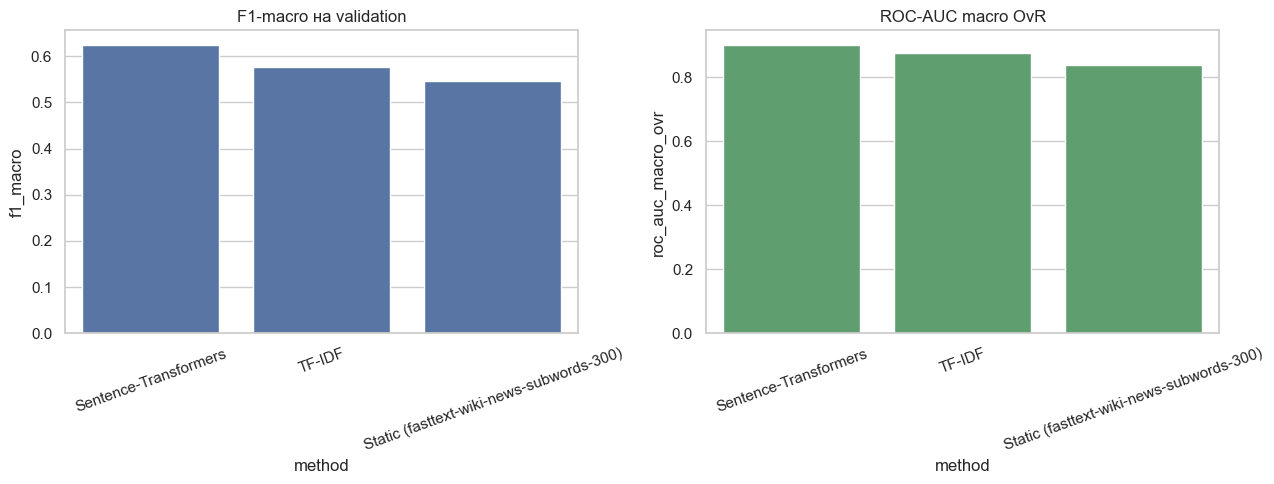

Сохранено: reports\lab4\figures\method_comparison.png


In [7]:
validation_comparison = pd.DataFrame([
    {"method": "TF-IDF", **tfidf_search.iloc[0][["accuracy", "f1_macro", "roc_auc_macro_ovr", "fit_seconds"]].to_dict()},
    {"method": f"Static ({static_vectors_name})", **static_search.iloc[0][["accuracy", "f1_macro", "roc_auc_macro_ovr", "fit_seconds"]].to_dict()},
    {"method": "Sentence-Transformers", **sentence_search.iloc[0][["accuracy", "f1_macro", "roc_auc_macro_ovr", "fit_seconds"]].to_dict()},
]).sort_values(["f1_macro", "roc_auc_macro_ovr"], ascending=False)
validation_comparison.to_csv(REPORT_DIR / "method_comparison.csv", index=False)
display(validation_comparison)
best_method = validation_comparison.iloc[0]["method"]
print(f"Лучший метод по validation F1-macro: {best_method}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.barplot(data=validation_comparison, x="method", y="f1_macro", ax=axes[0], color="#4C72B0")
axes[0].set_title("F1-macro на validation"); axes[0].tick_params(axis="x", rotation=20)
sns.barplot(data=validation_comparison, x="method", y="roc_auc_macro_ovr", ax=axes[1], color="#55A868")
axes[1].set_title("ROC-AUC macro OvR"); axes[1].tick_params(axis="x", rotation=20)
save_figure("method_comparison.png")

## 8. Финальное обучение и оценка на test

После выбора метода train и validation объединяются. Все три подхода также
переобучаются для прозрачной итоговой таблицы, но выбор лучшего метода уже
зафиксирован по validation.

,method,accuracy,f1_macro,roc_auc_macro_ovr
2,Sentence-Transformers,0.600817,0.604025,0.888096
0,TF-IDF,0.564033,0.567444,0.865090
1,Static (fasttext-wiki-news-subwords-300),0.520436,0.525788,0.844884


,precision,recall,f1-score,support
anger,0.475000,0.532710,0.502203,107.000000
disgust,0.600000,0.593750,0.596859,96.000000
fear,0.771084,0.680851,0.723164,94.000000
guilt,0.579439,0.529915,0.553571,117.000000
joy,0.680328,0.813725,0.741071,102.000000
sadness,0.534653,0.586957,0.559585,92.000000
shame,0.603774,0.507937,0.551724,126.000000
accuracy,0.600817,0.600817,0.600817,0.600817
macro avg,0.606326,0.606549,0.604025,734.000000
weighted avg,0.604030,0.600817,0.599956,734.000000


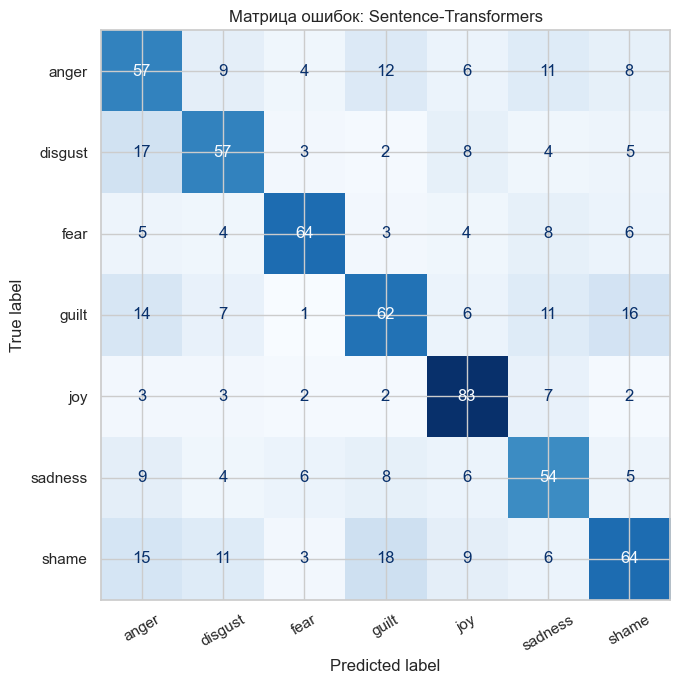

Сохранено: reports\lab4\figures\confusion_matrix.png


In [8]:
train_val_df = pd.concat([train_df, validation_df], ignore_index=True)
y_train_val = np.concatenate([y_train, y_validation])

# TF-IDF
final_tfidf = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), max_features=10000,
                              min_df=2, sublinear_tf=True)),
    ("classifier", LogisticRegression(C=best_tfidf_c, max_iter=3000,
                                      random_state=RANDOM_STATE)),
])
final_tfidf.fit(train_val_df["clean_text"], y_train_val)

# Static embeddings
static_train_val = np.vstack([static_train, static_validation])
final_static = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(C=best_static_c, max_iter=3000,
                                      random_state=RANDOM_STATE)),
])
final_static.fit(static_train_val, y_train_val)

# Sentence embeddings
sentence_train_val = np.vstack([sentence_train, sentence_validation])
final_sentence = LogisticRegression(C=best_sentence_c, max_iter=3000,
                                    random_state=RANDOM_STATE)
final_sentence.fit(sentence_train_val, y_train_val)

test_inputs = {
    "TF-IDF": (final_tfidf, test_df["clean_text"]),
    f"Static ({static_vectors_name})": (final_static, static_test),
    "Sentence-Transformers": (final_sentence, sentence_test),
}
test_rows = []
test_predictions = {}
for method, (model, test_input) in test_inputs.items():
    pred = model.predict(test_input); proba = model.predict_proba(test_input)
    test_predictions[method] = (pred, proba)
    test_rows.append({
        "method": method,
        "accuracy": accuracy_score(y_test, pred),
        "f1_macro": f1_score(y_test, pred, average="macro"),
        "roc_auc_macro_ovr": roc_auc_score(y_test, proba,
                                            multi_class="ovr", average="macro"),
    })
test_comparison = pd.DataFrame(test_rows).sort_values("f1_macro", ascending=False)
test_comparison.to_csv(REPORT_DIR / "test_comparison.csv", index=False)
display(test_comparison)

final_method = best_method
final_model, final_input = test_inputs[final_method]
y_pred, y_proba = test_predictions[final_method]
accuracy = accuracy_score(y_test, y_pred)
f1_macro = f1_score(y_test, y_pred, average="macro")
roc_auc = roc_auc_score(y_test, y_proba, multi_class="ovr", average="macro")
cm = confusion_matrix(y_test, y_pred)

class_report = pd.DataFrame(classification_report(
    y_test, y_pred, target_names=class_names, output_dict=True,
    zero_division=0)).T
class_report.to_csv(REPORT_DIR / "classification_report.csv")
display(class_report)

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
    ax=ax, cmap="Blues", colorbar=False, xticks_rotation=30)
ax.set_title(f"Матрица ошибок: {final_method}")
save_figure("confusion_matrix.png")

## 9. PCA → t-SNE и PCA → UMAP

Визуализируются эмбеддинги лучшего метода. Для TF-IDF используется плотное
PCA-представление; для остальных — готовые плотные эмбеддинги. Размерность
сначала снижается до 50, затем строятся t-SNE и UMAP.

  File "C:\Users\Доктор Варвар\Desktop\все\MWwithD\.venv\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\Доктор Варвар\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Доктор Варвар\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\Доктор Варвар\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


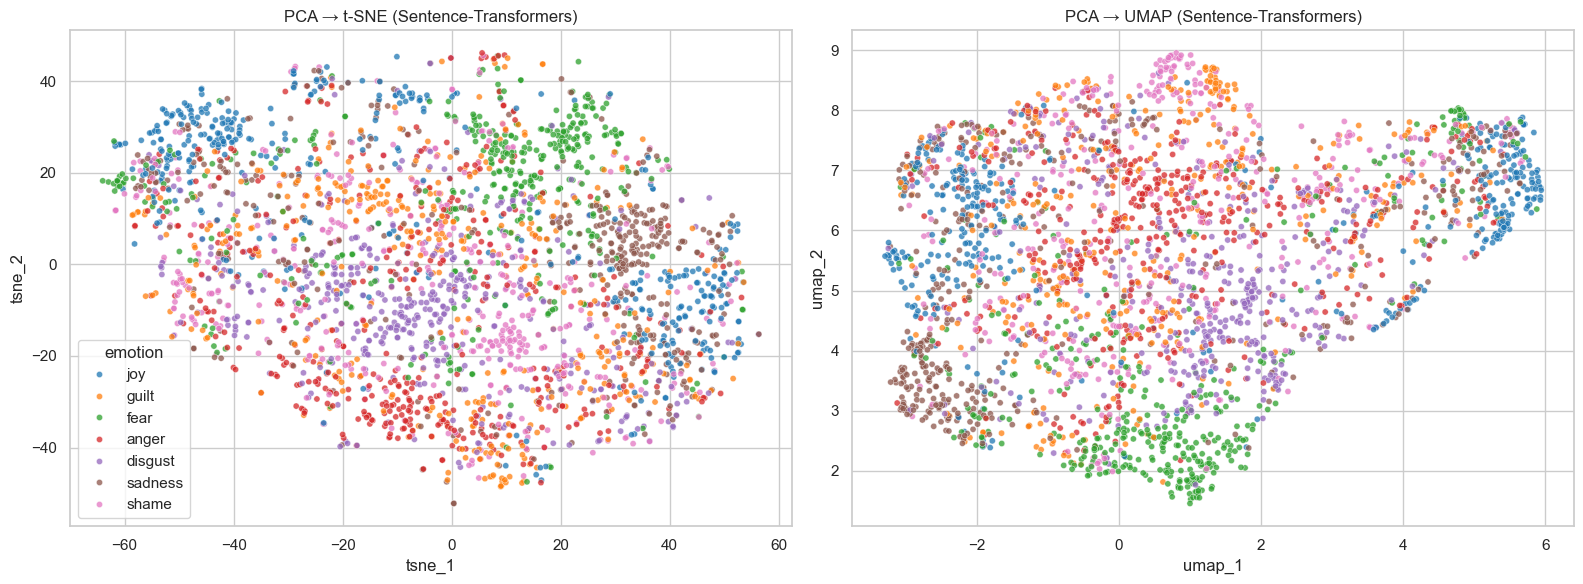

Сохранено: reports\lab4\figures\tsne_umap_embeddings.png


In [9]:
if best_method == "TF-IDF":
    visualization_vectors = final_tfidf.named_steps["tfidf"].transform(
        pd.concat([train_val_df["clean_text"], test_df["clean_text"]]))
    visualization_vectors = visualization_vectors.toarray()
elif best_method.startswith("Static"):
    visualization_vectors = np.vstack([static_train_val, static_test])
else:
    visualization_vectors = np.vstack([sentence_train_val, sentence_test])

visualization_labels = np.concatenate([y_train_val, y_test])
sample_size = min(3000, len(visualization_vectors))
sample_rng = np.random.default_rng(RANDOM_STATE)
sample_indices = sample_rng.choice(len(visualization_vectors), sample_size, replace=False)
sample_vectors = visualization_vectors[sample_indices]
sample_labels = visualization_labels[sample_indices]

n_components = min(50, sample_vectors.shape[1], sample_vectors.shape[0] - 1)
pca_50 = PCA(n_components=n_components, random_state=RANDOM_STATE).fit_transform(sample_vectors)
explained_variance = float(PCA(n_components=n_components, random_state=RANDOM_STATE)
                           .fit(sample_vectors).explained_variance_ratio_.sum())

tsne_points = TSNE(n_components=2, perplexity=30, init="pca",
                   learning_rate="auto", random_state=RANDOM_STATE).fit_transform(pca_50)
umap_points = umap.UMAP(n_components=2, n_neighbors=20, min_dist=0.15,
                        metric="cosine", random_state=RANDOM_STATE).fit_transform(pca_50)

visual_df = pd.DataFrame({
    "tsne_1": tsne_points[:, 0], "tsne_2": tsne_points[:, 1],
    "umap_1": umap_points[:, 0], "umap_2": umap_points[:, 1],
    "emotion": label_encoder.inverse_transform(sample_labels),
})

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.scatterplot(data=visual_df, x="tsne_1", y="tsne_2", hue="emotion",
                palette="tab10", s=20, alpha=0.75, ax=axes[0])
axes[0].set_title(f"PCA → t-SNE ({best_method})")
sns.scatterplot(data=visual_df, x="umap_1", y="umap_2", hue="emotion",
                palette="tab10", s=20, alpha=0.75, ax=axes[1])
axes[1].set_title(f"PCA → UMAP ({best_method})")
axes[1].legend_.remove()
save_figure("tsne_umap_embeddings.png")

## 10. Сохранение модели, DVC и аналитический отчёт

In [10]:
model_path = MODEL_DIR / "isear_lab4_classifier.pkl"
model_bundle = {
    "method": final_method,
    "classifier": final_model,
    "label_encoder": label_encoder,
    "sentence_model_name": sentence_model_name if final_method == "Sentence-Transformers" else None,
    "static_vectors_name": static_vectors_name if final_method.startswith("Static") else None,
    "preprocess": "lowercase, punctuation removal, English stop-word removal",
}
with model_path.open("wb") as file:
    cloudpickle.dump(model_bundle, file)
with model_path.open("rb") as file:
    loaded_bundle = cloudpickle.load(file)
assert loaded_bundle["method"] == final_method

metrics = {
    "variant": 10,
    "dataset": "ISEAR filtered",
    "classes": class_names,
    "device": DEVICE,
    "train_rows": len(train_df),
    "validation_rows": len(validation_df),
    "test_rows": len(test_df),
    "selected_method": final_method,
    "test_accuracy": round(float(accuracy), 6),
    "test_f1_macro": round(float(f1_macro), 6),
    "test_roc_auc_macro_ovr": round(float(roc_auc), 6),
    "pca_explained_variance_50": round(explained_variance, 6),
}
(REPORT_DIR / "model_metrics.json").write_text(
    json.dumps(metrics, ensure_ascii=False, indent=2), encoding="utf-8")

def run_command(command):
    result = subprocess.run(command, cwd=PROJECT_ROOT, capture_output=True,
                            text=True, encoding="utf-8", errors="replace")
    print(f"$ {' '.join(map(str, command))}")
    if result.stdout.strip(): print(result.stdout.strip())
    if result.stderr.strip(): print(result.stderr.strip())
    return result

for artifact in (raw_path, train_path, validation_path, test_path, model_path):
    result = run_command([sys.executable, "-m", "dvc", "add", str(artifact)])
    if result.returncode != 0:
        raise RuntimeError(f"DVC не смог добавить {artifact}")
dvc_status = run_command([sys.executable, "-m", "dvc", "status"])

best_validation = validation_comparison.iloc[0]
test_best_row = test_comparison[test_comparison["method"] == final_method].iloc[0]
n_errors = int((y_pred != y_test).sum())
best_class = class_report.loc[class_names, "f1-score"].idxmax()
hardest_class = class_report.loc[class_names, "f1-score"].idxmin()

report_path = REPORT_DIR / "lab4_summary.md"
report_path.write_text(f"""# Отчёт по лабораторной работе №4

## Постановка задачи

Для варианта 10 решена задача распознавания семи эмоций ISEAR по текстовому
описанию ситуации. Сравнены TF-IDF, статические предобученные эмбеддинги и
современные Sentence-Transformer эмбеддинги. Для лучшего представления
построены PCA → t-SNE и PCA → UMAP.

## Данные и предобработка

Использована конфигурация `filtered` датасета `savalera/isear-from-original`:
{len(all_df)} корректных описания. Разбиение источника сохранено: {len(train_df)}
train, {len(validation_df)} validation и {len(test_df)} test. Классы: {', '.join(class_names)}.
Для TF-IDF и статических эмбеддингов выполнены нижний регистр, удаление
пунктуации и стоп-слов. Контекстная модель получила минимально очищенный текст.

## TF-IDF baseline

Использованы униграммы и биграммы, максимум 10 000 признаков и логистическая
регрессия. Лучшее C={best_tfidf_c}. Метод служит сильным разреженным baseline и
учитывает конкретные слова и устойчивые биграммы, но не понимает контекст.

## Статические эмбеддинги

Использованы `{static_vectors_name}` размерности {STATIC_DIM}, загруженные через
gensim. Документ представлен средним вектором известных слов; среднее покрытие
словаря train равно {coverage_train.mean():.3f}. Такой подход учитывает
семантическую близость слов, но теряет порядок и контекст.

## Sentence-Transformers

Модель `all-MiniLM-L6-v2` сформировала контекстные векторы размерности
{sentence_train.shape[1]}. Устройство: **{DEVICE}**. Время кодирования трёх
частей составило {sentence_encoding_seconds:.1f} секунды.

## Сравнение методов

Лучший метод по validation F1-macro — **{final_method}** со значением
{best_validation['f1_macro']:.4f} и ROC-AUC {best_validation['roc_auc_macro_ovr']:.4f}.
После переобучения на train+validation итоговые метрики на test:

| Метрика | Значение |
|---|---:|
| Accuracy | {accuracy:.4f} |
| F1-macro | {f1_macro:.4f} |
| ROC-AUC macro OvR | {roc_auc:.4f} |

Количество ошибок: {n_errors} из {len(y_test)}. Лучше всего распознаётся класс
**{best_class}**, наиболее сложным оказался **{hardest_class}**. Подробные
метрики находятся в `classification_report.csv`.

## PCA, t-SNE и UMAP

Для визуализации использованы эмбеддинги метода **{final_method}**. После PCA до
{n_components} компонент сохранено {explained_variance:.1%} дисперсии. t-SNE
подчёркивает локальные группы похожих описаний, UMAP лучше показывает общую
структуру и переходы между эмоциями. Частичное пересечение кластеров ожидаемо:
одна ситуация может содержать признаки нескольких близких эмоций.

## Соответствие требованиям

- Построен TF-IDF с униграммами, биграммами и `max_features=10000`.
- Обучена логистическая регрессия и рассчитаны accuracy, F1-macro, ROC-AUC.
- Загружены статические предобученные эмбеддинги через gensim.
- Получены усреднённые векторы документов и оценена модель.
- Использована Sentence-Transformer `all-MiniLM-L6-v2`.
- Все три подхода сведены в сравнительные таблицы.
- Для лучшего метода выполнены PCA → t-SNE и PCA → UMAP.
- GPU используется автоматически при наличии; в текущем запуске устройство {DEVICE}.
- Данные и итоговая модель добавлены под контроль DVC.

## Вывод

Эксперимент показывает, какой способ представления текста лучше различает семь
эмоций ISEAR при одинаковом классификаторе. Выбор выполнен по validation, а test
использован для финальной оценки. Таблицы, графики, модель и параметры запуска
сохранены в воспроизводимой структуре проекта.
""", encoding="utf-8")

print(json.dumps(metrics, ensure_ascii=False, indent=2))
print(f"Модель: {model_path.relative_to(PROJECT_ROOT)}")
print(f"Отчёт: {report_path.relative_to(PROJECT_ROOT)}")
print("Лабораторная работа №4 выполнена успешно.")

$ C:\Users\Доктор Варвар\Desktop\все\MWwithD\.venv\Scripts\python.exe -m dvc add C:\Users\Доктор Варвар\Desktop\все\MWwithD\data\raw\isear_lab4.csv
To track the changes with git, run:

	git add 'data\raw\isear_lab4.csv.dvc'

To enable auto staging, run:

	dvc config core.autostage true
\u280b Checking graph


$ C:\Users\Доктор Варвар\Desktop\все\MWwithD\.venv\Scripts\python.exe -m dvc add C:\Users\Доктор Варвар\Desktop\все\MWwithD\data\processed\lab4\train.csv
To track the changes with git, run:

	git add 'data\processed\lab4\train.csv.dvc'

To enable auto staging, run:

	dvc config core.autostage true
\u280b Checking graph


$ C:\Users\Доктор Варвар\Desktop\все\MWwithD\.venv\Scripts\python.exe -m dvc add C:\Users\Доктор Варвар\Desktop\все\MWwithD\data\processed\lab4\validation.csv
To track the changes with git, run:

	git add 'data\processed\lab4\validation.csv.dvc'

To enable auto staging, run:

	dvc config core.autostage true
\u280b Checking graph


$ C:\Users\Доктор Варвар\Desktop\все\MWwithD\.venv\Scripts\python.exe -m dvc add C:\Users\Доктор Варвар\Desktop\все\MWwithD\data\processed\lab4\test.csv
To track the changes with git, run:

	git add 'data\processed\lab4\test.csv.dvc'

To enable auto staging, run:

	dvc config core.autostage true
\u280b Checking graph


$ C:\Users\Доктор Варвар\Desktop\все\MWwithD\.venv\Scripts\python.exe -m dvc add C:\Users\Доктор Варвар\Desktop\все\MWwithD\models\isear_lab4_classifier.pkl
To track the changes with git, run:

	git add 'models\isear_lab4_classifier.pkl.dvc'

To enable auto staging, run:

	dvc config core.autostage true
\u280b Checking graph


$ C:\Users\Доктор Варвар\Desktop\все\MWwithD\.venv\Scripts\python.exe -m dvc status
data\raw\sample_customers.csv.dvc:
	changed outs:
		not in cache:       data\raw\sample_customers.csv
{
  "variant": 10,
  "dataset": "ISEAR filtered",
  "classes": [
    "anger",
    "disgust",
    "fear",
    "guilt",
    "joy",
    "sadness",
    "shame"
  ],
  "device": "cpu",
  "train_rows": 5853,
  "validation_rows": 732,
  "test_rows": 734,
  "selected_method": "Sentence-Transformers",
  "test_accuracy": 0.600817,
  "test_f1_macro": 0.604025,
  "test_roc_auc_macro_ovr": 0.888096,
  "pca_explained_variance_50": 0.621361
}
Модель: models\isear_lab4_classifier.pkl
Отчёт: reports\lab4\lab4_summary.md
Лабораторная работа №4 выполнена успешно.
